# 01 - Exploración de datos (EDA)

**Reorganizado el 26/09/2026 dentro de `PROYECTO_ESTRUCTURADO/` a partir de `02_desercion_eda_prep.ipynb`** (carpeta de trabajo original). Este notebook contiene, sin cambios de fondo, las secciones 1 a 4 del original: entorno, carga del parquet cacheado (generado por `01_desercion_dataset.ipynb`, que no se reconstruye aún en esta estructura porque la recolección no forma parte de exploración/preprocesamiento/modelado/optimización/evaluación) y el EDA completo (integridad estructural, estabilidad temporal, censura, tasas base, distribuciones, correlaciones, categóricas, fuga de información y resumen de hallazgos).

El preprocesamiento (partición, pipelines, guardado de artefactos) sigue en `02_preprocesamiento.ipynb`.

# Predicción de deserción de clientes — Retail farmacéutico
## 2/2 — EDA, limpieza, tratamiento y normalización

**Proyecto de tesis** · Maestría en Inteligencia Artificial
**Autores:** Henry Medina (analista de datos y bases de datos) · William Andrade (desarrollador)

---

Continúa desde **`01_desercion_dataset.ipynb`**, que construye el dataset y lo
guarda en `datos/ds_desercion_real.parquet`. Este notebook parte de ese
parquet directamente (no abre conexión a la base ni vuelve a leer las
tablas), para no repetir la consulta cada vez que se reinicia el kernel.

### Contenido

4. Análisis exploratorio
5. Codificación y normalización

### Reescrito 20/09/2026 para el esquema de 16 columnas

Las secciones 4 y 5 se reescribieron por completo para el SQL simplificado
del 19/09/2026 (`recency_dias`, `monto_total_12m`, `churn`, etc. — ver
`CONTEXTO_PROYECTO.md`, sección 6). Ya no referencian el diseño anterior de 31
features y 3 etiquetas (`y_evento`, `gap_medio_dias`, `pdv_principal`, etc.).
Dos cosas cambiaron de fondo, no solo de nombre:

- **`segmento_frecuencia` ya no viene del SQL.** El diseño simplificado no la
  calcula, así que se reconstruye aquí mismo en pandas a partir de
  `n_visitas_12m`, con los mismos tramos medidos en `CONTEXTO_PROYECTO.md`
  (baja 4–6, media 7–12, alta 13+).
- **La comparación contra una regla fija de 90 días (antes 4.10) ya no es
  reproducible tal cual.** El SQL simplificado no guarda `max_gap_pred` ni un
  resultado paralelo con esa regla; solo la etiqueta `churn` (umbral
  personalizado). La sección 4.10 quedó como una descripción parcial (qué tan
  lejos está el umbral propio de 90 días), no como el cruce de resultados que
  había antes.

In [1]:
# ====================== ENTORNO ======================
# La recolección (conexión a la base, SQL, caché) se hace en
# 01_desercion_dataset.ipynb. Aquí solo se prepara lo necesario para leer
# el parquet ya generado: no se abre ninguna conexión a la base.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9})

DIR_DATOS = Path("datos");      DIR_DATOS.mkdir(exist_ok=True)
DIR_SALIDA = Path("salidas");   DIR_SALIDA.mkdir(exist_ok=True)
DIR_ART = Path("artefactos");   DIR_ART.mkdir(exist_ok=True)

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# mismo interruptor que en 01_desercion_dataset.ipynb: decide qué parquet leer
USAR_BASE_REAL = True      # False = ds_desercion_sintetico.parquet · True = ds_desercion_real.parquet
print("modo:", "BASE REAL" if USAR_BASE_REAL else "SINTÉTICO")

# PARAMS y CORTES no hacen falta para leer el parquet (ya están "horneados"
# en las filas), pero 5.6 los guarda como metadata junto con el joblib de
# preprocesamiento, así que se redefinen aquí, idénticos a
# 01_desercion_dataset.ipynb (sin volver a tocar la base).
PARAMS = {
    "obs_meses":     12,
    "pred_dias":     120,
    "min_visitas":   4,
    "percentil":     0.90,
    "piso_dias":     14,
    "techo_dias":    180,
    "max_dias_anio":     150,
    "max_fact_por_dia":  3.0,
    "muestra_k":     10,
}
CORTES = [
    {"id": "C1", "fecha": "2024-12-31", "uso": "train"},
    {"id": "C2", "fecha": "2025-04-30", "uso": "train"},
    {"id": "C3", "fecha": "2025-08-31", "uso": "train"},
    {"id": "C4", "fecha": "2025-12-31", "uso": "validacion"},
    {"id": "C5", "fecha": "2026-04-30", "uso": "test"},
]

modo: BASE REAL


In [2]:
# ===================== CARGA DEL DATASET YA CONSTRUIDO =========================
RUTA_CACHE = DIR_DATOS / ("ds_desercion_real.parquet" if USAR_BASE_REAL
                          else "ds_desercion_sintetico.parquet")

if not RUTA_CACHE.exists():
    raise FileNotFoundError(
        f"No se encontró {RUTA_CACHE}. Corre primero 01_desercion_dataset.ipynb "
        "(con USAR_BASE_REAL en el mismo valor) para generar el parquet."
    )

df = pd.read_parquet(RUTA_CACHE)
print("leído:", RUTA_CACHE)
print(f"filas: {len(df):,}   columnas: {df.shape[1]}   "
      f"clientes únicos: {df['id_cliente'].nunique():,}")
df.head(3)

leído: datos\ds_desercion_real.parquet
filas: 2,417,698   columnas: 21   clientes únicos: 767,457


,fecha_corte,id_cliente,fecha_ultima_compra,recency_dias,n_visitas_12m,n_dias_activo_12m,monto_total_12m,ticket_promedio,tendencia_gasto,pct_gasto_cronico_12m,es_comprador_cronico,n_categorias_distintas_12m,n_bodegas_distintas_12m,antiguedad_meses,metodo_pago_principal_12m,n_metodos_pago_distintos_12m,umbral_propio_dias,censurado,churn,corte_id,uso
0,2024-12-31,1729,2024-11-15,46,5,5,47.3900,9.4780,8.9975,0.0000,False,3,4,13,EFE,1,157,1,NaN,C1,train
1,2024-12-31,1743,2024-11-06,55,4,4,7.8000,1.9500,0.5135,0.0000,False,4,3,13,EFE,1,105,0,0.0000,C1,train
2,2024-12-31,1812,2024-06-15,199,22,17,292.9000,13.3136,0.0000,0.0000,False,5,3,13,EFE,2,22,0,1.0000,C1,train


---
# 4. Análisis exploratorio

El orden no es casual. Primero se verifica que el dataset esté bien construido
(4.1–4.3), porque un error ahí invalida todo lo demás. Después se estudia el
fenómeno (4.4–4.9). Al final se acota lo que ya no se puede reproducir con el
esquema simplificado y se buscan los problemas que arruinan proyectos de este
tipo (4.10–4.11).

**Nota (20/09/2026):** esta sección se reescribió para el esquema de 16
columnas del SQL simplificado (ver `CONTEXTO_PROYECTO.md`, secciones 5 y 6).
El diseño anterior de 31 features y 3 etiquetas (`y_evento`, `y_estado`,
`y_fijo90`, `max_gap_pred`, `segmento_frecuencia` como columna del SQL,
`pdv_principal`, `linea_top`, `sexo`, `cambio_bodega_3m`, etc.) ya no existe.
Los cambios principales: la etiqueta única ahora es `churn`; `segmento_frecuencia`
se reconstruye en pandas a partir de `n_visitas_12m` (ya no viene del SQL); y
la comparación contra una regla fija de 90 días (4.10 en el diseño anterior)
ya no es reproducible tal cual, porque el SQL simplificado no guarda el
resultado de esa regla — se documenta como limitación en su lugar.

In [3]:
# ===================== GRUPOS DE COLUMNAS (esquema de 16 columnas, 20/09/2026) =========================
# segmento_frecuencia ya no viene del SQL (el diseño simplificado no la calcula).
# Se reconstruye aquí con los mismos tramos medidos en CONTEXTO_PROYECTO.md
# (sección 2.2): baja 4-6 visitas/año, media 7-12, alta 13+. El SQL ya filtra
# n_visitas_12m >= PARAMS["min_visitas"] (4), así que no hay tramo por debajo.
def _segmentar(n):
    if n <= 6:
        return "1. baja"
    elif n <= 12:
        return "2. media"
    return "3. alta"

df["segmento_frecuencia"] = df["n_visitas_12m"].apply(_segmentar)

# SQL Server CAST(...AS bit) llega como bool de Python/pandas; describe(),
# .quantile() y .skew() no operan sobre bool (numpy no permite restarlos),
# así que se castea a entero apenas se define como feature numérica.
df["es_comprador_cronico"] = df["es_comprador_cronico"].astype(int)

COLS_CONTROL = ["id_cliente", "fecha_corte", "fecha_ultima_compra", "corte_id",
                "uso", "segmento_frecuencia", "censurado"]
COLS_ETIQUETA = ["churn"]          # única etiqueta en el esquema simplificado
TARGET = "churn"

FEAT_NUM = [
    # ritmo y actividad
    "recency_dias", "n_visitas_12m", "n_dias_activo_12m",
    # monetario
    "monto_total_12m", "ticket_promedio", "tendencia_gasto",
    # canasta farmacéutica
    "pct_gasto_cronico_12m", "es_comprador_cronico",
    # variedad y antigüedad
    "n_categorias_distintas_12m", "n_bodegas_distintas_12m", "antiguedad_meses",
    # pago
    "n_metodos_pago_distintos_12m",
    # umbral propio (participa de la etiqueta, ver 4.11)
    "umbral_propio_dias",
]
FEAT_CAT = ["metodo_pago_principal_12m"]   # única categórica que sobrevive al SQL simplificado
FEATURES = FEAT_NUM + FEAT_CAT

faltan = [c for c in COLS_CONTROL + COLS_ETIQUETA + FEATURES if c not in df.columns]
sobran = [c for c in df.columns if c not in COLS_CONTROL + COLS_ETIQUETA + FEATURES]
print(f"features numéricas : {len(FEAT_NUM)}")
print(f"features categóricas: {len(FEAT_CAT)}")
print(f"total features      : {len(FEATURES)}")
if faltan: print("FALTAN en el dataframe:", faltan)
if sobran: print("columnas no clasificadas:", sobran)

features numéricas : 13
features categóricas: 1
total features      : 14


## 4.1 Integridad estructural

Cuatro comprobaciones que deben pasar antes de mirar cualquier distribución.

In [4]:
print("— forma —")
print(f"{len(df):,} filas × {df.shape[1]} columnas")
print(f"memoria: {df.memory_usage(deep=True).sum()/1e6:,.1f} MB\n")

print("— unicidad de la llave (id_cliente, fecha_corte) —")
dups = df.duplicated(subset=["id_cliente", "fecha_corte"]).sum()
print("duplicados:", dups, "→", "OK" if dups == 0 else "REVISAR")

print("\n— apariciones por cliente (esperado 1 a 5) —")
ap = df.groupby("id_cliente").size().value_counts().sort_index()
print(ap.rename("clientes").to_frame().assign(
    pct=lambda t: (100*t["clientes"]/t["clientes"].sum()).round(2)).to_string())

print("\n— nulos —")
nul = (df.isna().sum().rename("nulos").to_frame()
       .assign(pct=lambda t: (100*t["nulos"]/len(df)).round(2))
       .query("nulos > 0").sort_values("nulos", ascending=False))
print(nul.to_string() if len(nul) else "sin nulos")

print("\n— valores infinitos en features numéricas —")
inf = {c: int(np.isinf(df[c].to_numpy(dtype="float64", na_value=np.nan)).sum())
       for c in FEAT_NUM}
inf = {k: v for k, v in inf.items() if v}
print(inf if inf else "sin infinitos")

— forma —
2,417,698 filas × 22 columnas
memoria: 1,020.7 MB

— unicidad de la llave (id_cliente, fecha_corte) —
duplicados: 0 → OK

— apariciones por cliente (esperado 1 a 5) —
   clientes     pct
1    149867 19.5300
2    141686 18.4600
3    144152 18.7800
4    106757 13.9100
5    224995 29.3200

— nulos —
                  nulos     pct
churn            382498 15.8200
tendencia_gasto   39875  1.6500

— valores infinitos en features numéricas —
sin infinitos


El SQL simplificado calcula todos los cocientes con `NULLIF` en el denominador
(`ticket_promedio`, `tendencia_gasto`, `pct_gasto_cronico_12m`), así que un
denominador en cero produce `NULL` (nulo en pandas), no infinito. Por eso no se
esperan infinitos aquí — si aparecieran, sería señal de un cambio en el SQL que
haya reintroducido una división sin `NULLIF`. Los nulos genuinos (denominador
en cero) se tratan junto con los outliers en 4.6.

## 4.2 Estabilidad temporal

**La comprobación más importante del EDA.** La tasa base debe ser parecida en los
cinco cortes. Si un corte se dispara o se hunde, casi siempre indica un cambio de
sistema, una promoción atípica o una carga incompleta del data warehouse, y hay
que investigarlo antes de entrenar: un modelo aprendido sobre un período anómalo
no generaliza.

corte_id        uso  filas  entrenables  pct_censura  tasa_churn
      C1      train 413446       338809      18.0500     35.2700
      C2      train 448462       367774      17.9900     35.7900
      C3      train 491879       430953      12.3900     40.2700
      C4 validacion 537463       453594      15.6000     41.8700
      C5       test 526448       444070      15.6500     40.1100

rango de la tasa base entre cortes: 6.60 puntos porcentuales
→ REVISAR: variación alta entre cortes


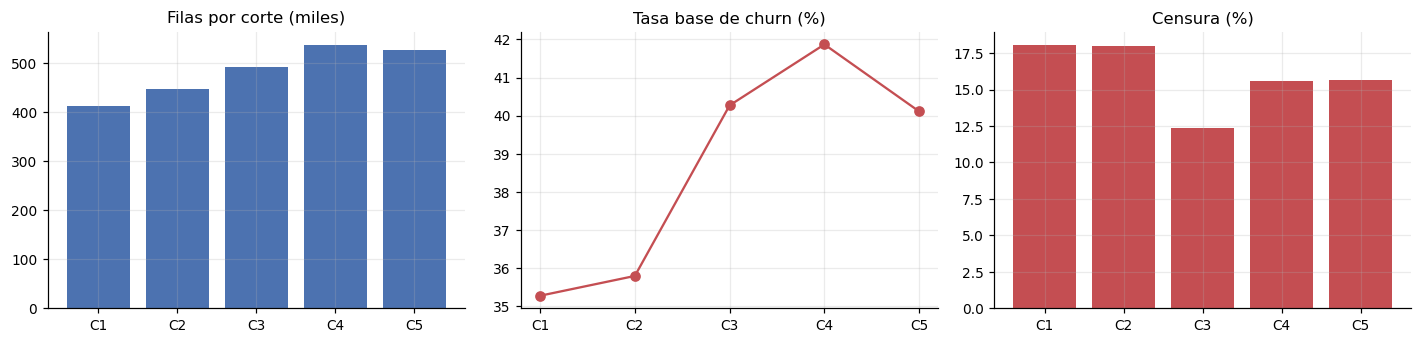

In [5]:
res = (df.groupby(["corte_id", "uso"], observed=True)
         .agg(filas=("id_cliente", "size"),
              clientes=("id_cliente", "nunique"),
              censurados=("censurado", "sum"),
              tasa_churn=("churn", "mean"))
         .reset_index())
res["pct_censura"] = (100*res["censurados"]/res["filas"]).round(2)
res["tasa_churn"]  = (100*res["tasa_churn"]).round(2)
res["entrenables"] = res["filas"] - res["censurados"]
print(res[["corte_id","uso","filas","entrenables","pct_censura",
           "tasa_churn"]].to_string(index=False))

rango = res["tasa_churn"].max() - res["tasa_churn"].min()
print(f"\nrango de la tasa base entre cortes: {rango:.2f} puntos porcentuales")
print("→", "estable" if rango < 5 else "REVISAR: variación alta entre cortes")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].bar(res["corte_id"], res["filas"]/1000, color="#4C72B0")
ax[0].set_title("Filas por corte (miles)")
ax[1].plot(res["corte_id"], res["tasa_churn"], "o-", color="#C44E52")
ax[1].set_title("Tasa base de churn (%)")
ax[2].bar(res["corte_id"], res["pct_censura"], color="#C44E52")
ax[2].set_title("Censura (%)")
plt.tight_layout(); plt.show()

## 4.3 Censura

Un cliente está censurado cuando su umbral propio supera la ventana de 120 días:
su deserción no es observable, su etiqueta sería 0 por aritmética de calendario y
no por comportamiento. Se excluyen del entrenamiento y **se reportan**.

Lo relevante no es el promedio global sino su distribución: la censura se
concentra entera en el segmento de baja frecuencia.

In [6]:
cen = (df.groupby("segmento_frecuencia", observed=True)
         .agg(clientes=("censurado", "size"),
              censurados=("censurado", "sum"),
              umbral_medio=("umbral_propio_dias", "mean")))
cen["pct_censura"] = (100*cen["censurados"]/cen["clientes"]).round(2)
cen["entrenables"] = cen["clientes"] - cen["censurados"]
print(cen.round(2).to_string())
print(f"\ncensura global ponderada: "
      f"{100*df['censurado'].mean():.2f} %")

# ---- a partir de aquí se trabaja solo con los entrenables ----
df_e = df.loc[df["censurado"] == 0].copy()

# caso límite: no censurado pero sin umbral propio calculable (menos de 2
# fechas distintas de compra en la ventana, así que no hay intervalo que
# percentilar). El SQL los deja con churn NULL; se reportan y se excluyen.
nulos_churn = int(df_e["churn"].isna().sum())
if nulos_churn:
    print(f"\nclientes no censurados con churn nulo (sin umbral propio "
          f"calculable): {nulos_churn} — se excluyen del set entrenable")
    df_e = df_e.loc[df_e["churn"].notna()].copy()
df_e["churn"] = df_e["churn"].astype(int)

print(f"\ndataset entrenable: {len(df_e):,} filas "
      f"({100*len(df_e)/len(df):.1f} % del total), "
      f"{df_e['id_cliente'].nunique():,} clientes únicos")

                     clientes  censurados  umbral_medio  pct_censura  entrenables
segmento_frecuencia                                                              
1. baja                999564      335243       98.8300      33.5400       664321
2. media               707612       46832       74.2000       6.6200       660780
3. alta                710522         423       35.2300       0.0600       710099

censura global ponderada: 15.82 %

dataset entrenable: 2,035,200 filas (84.2 % del total), 682,128 clientes únicos


## 4.4 Tasa base por subgrupo

`es_comprador_cronico` no es solo una feature: es la variable de estratificación
para el análisis de validez. Un comprador de medicación crónica que deja de
comprar puede haber terminado su tratamiento, cambiado de medicación o fallecido,
y ninguna campaña lo recupera. Si su tasa de deserción difiere de forma marcada,
conviene reportar las métricas del modelo por separado para ese grupo.

In [7]:
def tasa_por(col, dfx=None, orden=None):
    dfx = df_e if dfx is None else dfx
    t = (dfx.groupby(col, observed=True)[TARGET]
            .agg(n="size", desertores="sum", tasa="mean"))
    t["tasa_%"] = (100*t["tasa"]).round(2)
    t["pct_base"] = (100*t["n"]/len(dfx)).round(2)
    t = t.drop(columns="tasa")
    return t.reindex(orden) if orden else t

for col in ["segmento_frecuencia", "es_comprador_cronico", "metodo_pago_principal_12m"]:
    print(f"— {col} —")
    print(tasa_por(col).to_string(), "\n")

— segmento_frecuencia —
                          n  desertores  tasa_%  pct_base
segmento_frecuencia                                      
1. baja              664321      372746 56.1100   32.6400
2. media             660780      241611 36.5600   32.4700
3. alta              710099      178355 25.1200   34.8900 

— es_comprador_cronico —
                            n  desertores  tasa_%  pct_base
es_comprador_cronico                                       
0                     2010895      783124 38.9400   98.8100
1                       24305        9588 39.4500    1.1900 

— metodo_pago_principal_12m —
                                 n  desertores   tasa_%  pct_base
metodo_pago_principal_12m                                        
CEM                            446         238  53.3600    0.0200
CHQ                            758         360  47.4900    0.0400
CRA                              5           3  60.0000    0.0000
CRD                             95          15  15.7900  

## 4.5 Distribuciones univariadas

In [8]:
desc = df_e[FEAT_NUM].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["nulos_%"] = (100*df_e[FEAT_NUM].isna().mean()).round(2)
print(desc.round(3).to_string())

                                      count     mean      std           min      1%      5%     25%     50%      75%      95%      99%         max  nulos_%
recency_dias                 2,035,200.0000  57.6100  66.8860        0.0000  0.0000  1.0000  9.0000 30.0000  83.0000 206.0000 285.0000    365.0000   0.0000
n_visitas_12m                2,035,200.0000  15.0350  18.7030        4.0000  4.0000  4.0000  6.0000  9.0000  16.0000  46.0000  99.0000    433.0000   0.0000
n_dias_activo_12m            2,035,200.0000  13.5280  15.1880        2.0000  3.0000  4.0000  5.0000  8.0000  15.0000  41.0000  83.0000    149.0000   0.0000
monto_total_12m              2,035,200.0000 106.3620 199.2770        0.8100  6.0900 11.0800 26.3700 51.2400 107.8100 374.0970 901.4400 23,586.8820   0.0000
ticket_promedio              2,035,200.0000   6.9920   7.0890        0.1620  1.1000  1.7500  3.3570  5.1820   8.3080  17.7700  32.4310    878.1900   0.0000
tendencia_gasto              1,995,325.0000   2.0620 159.0140 -2

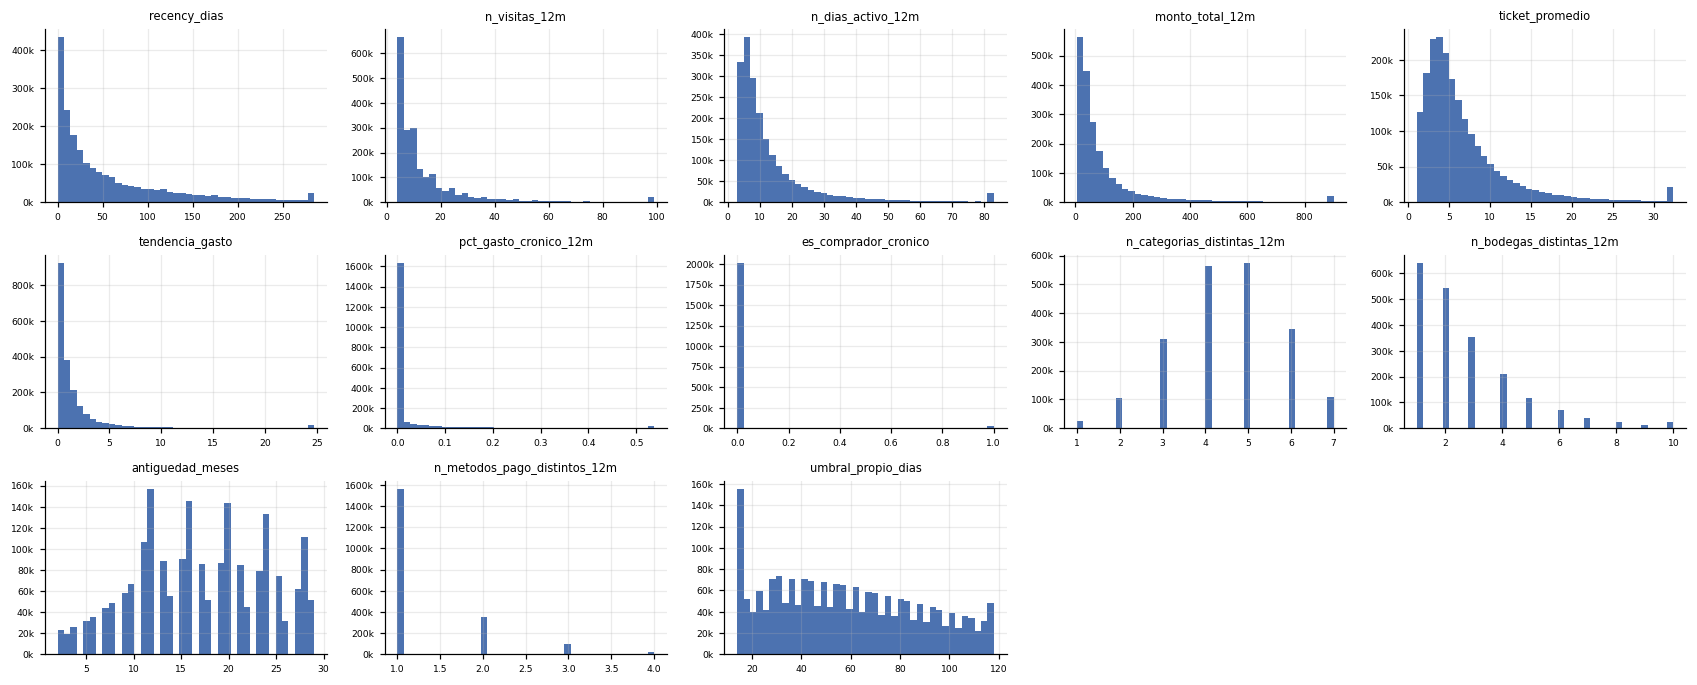

In [9]:
n = len(FEAT_NUM); ncol = 5; nrow = int(np.ceil(n/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.1*ncol, 2.1*nrow))
for ax, col in zip(axes.ravel(), FEAT_NUM):
    s = df_e[col].replace([np.inf, -np.inf], np.nan).dropna()
    # recorte visual al 1–99 % para que la cola no aplaste el gráfico
    lo, hi = s.quantile([.01, .99])
    ax.hist(s.clip(lo, hi), bins=40, color="#4C72B0", edgecolor="none")
    ax.set_title(col, fontsize=7.5); ax.tick_params(labelsize=6)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4.6 Asimetría y valores extremos

Importa solo para la regresión logística: los árboles parten por umbrales y les da
igual la escala o la forma de la distribución. Las columnas con asimetría por
encima de 2 son candidatas a transformación logarítmica en el pipeline B.

Se usa un logaritmo con signo, `sign(x)·log(1+|x|)`, porque `monto_total_12m`
puede ser negativo si las devoluciones superan la venta en la ventana de 12
meses. El resto de las columnas monetarias y de conteo (`ticket_promedio`,
`n_visitas_12m`, etc.) no toma valores negativos, pero el logaritmo con signo
las trata igual sin problema.

In [10]:
sk = (df_e[FEAT_NUM].replace([np.inf, -np.inf], np.nan)
        .skew().rename("asimetria").to_frame())
sk["curtosis"] = df_e[FEAT_NUM].replace([np.inf, -np.inf], np.nan).kurt()
sk["min"] = df_e[FEAT_NUM].min()
sk["max"] = df_e[FEAT_NUM].max()
sk["p99/p50"] = (df_e[FEAT_NUM].quantile(.99) /
                 df_e[FEAT_NUM].quantile(.50).replace(0, np.nan))
sk = sk.sort_values("asimetria", key=abs, ascending=False)
print(sk.round(3).to_string())

COLS_LOG = [c for c in FEAT_NUM
            if abs(df_e[c].replace([np.inf,-np.inf], np.nan).skew()) > 2
            and df_e[c].nunique() > 10]
print("\ncandidatas a log con signo:", COLS_LOG)

                               asimetria       curtosis           min         max  p99/p50
tendencia_gasto              -1,358.4020 1,893,721.2760 -221,688.6750 20,086.7010  34.1850
ticket_promedio                  12.1290       645.0780        0.1620    878.1900   6.2590
monto_total_12m                  12.0860       484.3050        0.8100 23,586.8820  17.5930
antiguedad_meses                  9.8810       190.5860        0.0000    252.0000   1.7060
es_comprador_cronico              8.9860        78.7480        0.0000      1.0000      NaN
pct_gasto_cronico_12m             4.8270        27.7640       -0.0000      1.0000      NaN
n_visitas_12m                     4.7410        35.5820        4.0000    433.0000  11.0000
n_dias_activo_12m                 3.7080        18.7170        2.0000    149.0000  10.3750
n_bodegas_distintas_12m           2.4000        14.4160        1.0000     68.0000   5.0000
n_metodos_pago_distintos_12m      2.3470         6.4060        1.0000      8.0000   4.0000

## 4.7 Correlaciones

Se buscan dos cosas: pares redundantes (una de las dos no aporta) y bloques de
variables que midan lo mismo. En un modelo de árboles la correlación no impide el
ajuste, pero reparte la importancia entre variables equivalentes y hace ilegible
la interpretación posterior.

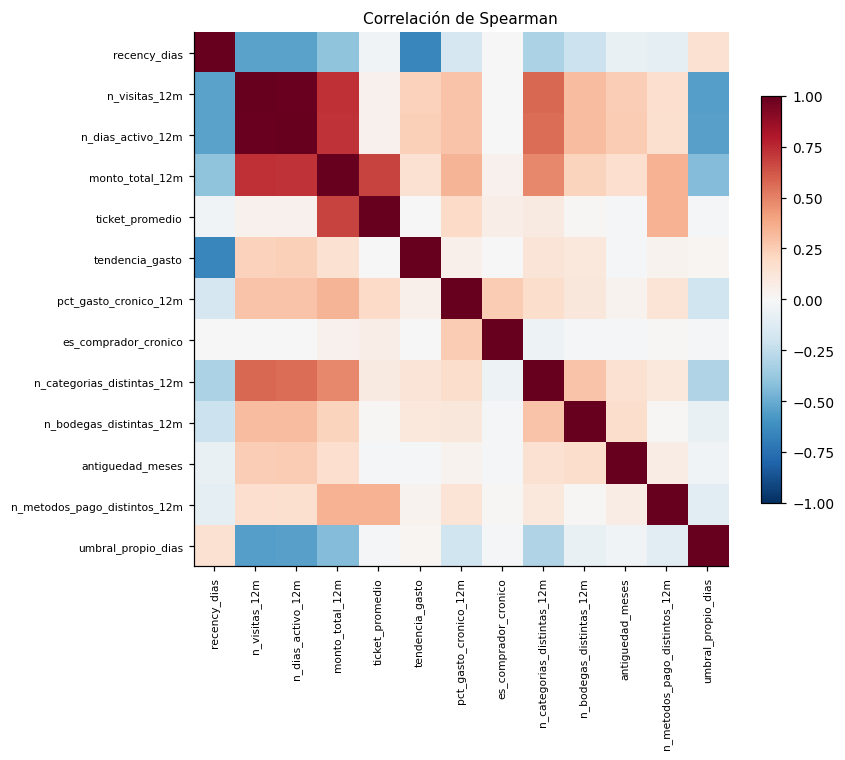

pares con |rho| > 0,75:
n_visitas_12m  n_dias_activo_12m   0.9860


In [11]:
num_ok = df_e[FEAT_NUM].replace([np.inf, -np.inf], np.nan)
corr = num_ok.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEAT_NUM))); ax.set_xticklabels(FEAT_NUM, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEAT_NUM))); ax.set_yticklabels(FEAT_NUM, fontsize=7)
ax.grid(False); plt.colorbar(im, shrink=.7)
ax.set_title("Correlación de Spearman", fontsize=10)
plt.tight_layout(); plt.show()

tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
altas = tri[tri.abs() > .75].sort_values(key=abs, ascending=False)
print("pares con |rho| > 0,75:")
print(altas.round(3).to_string() if len(altas) else "ninguno")

## 4.8 Relación de cada feature con la deserción

Más informativo que la correlación lineal: se divide cada variable en deciles y se
mide la tasa de deserción en cada uno. Una variable útil muestra una pendiente
clara; una inútil sale plana. Además detecta relaciones no monótonas, que la
correlación no vería.

In [12]:
def tasa_por_decil(col, dfx=None, q=10):
    dfx = df_e if dfx is None else dfx
    s = dfx[col].replace([np.inf, -np.inf], np.nan)
    try:
        b = pd.qcut(s, q, duplicates="drop")
    except ValueError:
        return None
    return dfx.assign(_b=b).groupby("_b", observed=True)[TARGET].agg(["size", "mean"])

# ordenar features por capacidad de separación (diferencia entre decil extremo)
poder = {}
for c in FEAT_NUM:
    t = tasa_por_decil(c)
    if t is not None and len(t) > 2:
        poder[c] = abs(t["mean"].iloc[-1] - t["mean"].iloc[0])
poder = pd.Series(poder).sort_values(ascending=False)
print("separación entre decil superior e inferior (puntos de tasa):")
print((100*poder).round(2).to_string())

separación entre decil superior e inferior (puntos de tasa):
recency_dias                 60.0000
n_dias_activo_12m            44.5600
n_visitas_12m                40.7600
tendencia_gasto              36.1200
monto_total_12m              36.0500
n_categorias_distintas_12m   27.9000
n_bodegas_distintas_12m      22.6800
antiguedad_meses             20.8200
umbral_propio_dias            7.8000
pct_gasto_cronico_12m         7.1500
ticket_promedio               6.3600


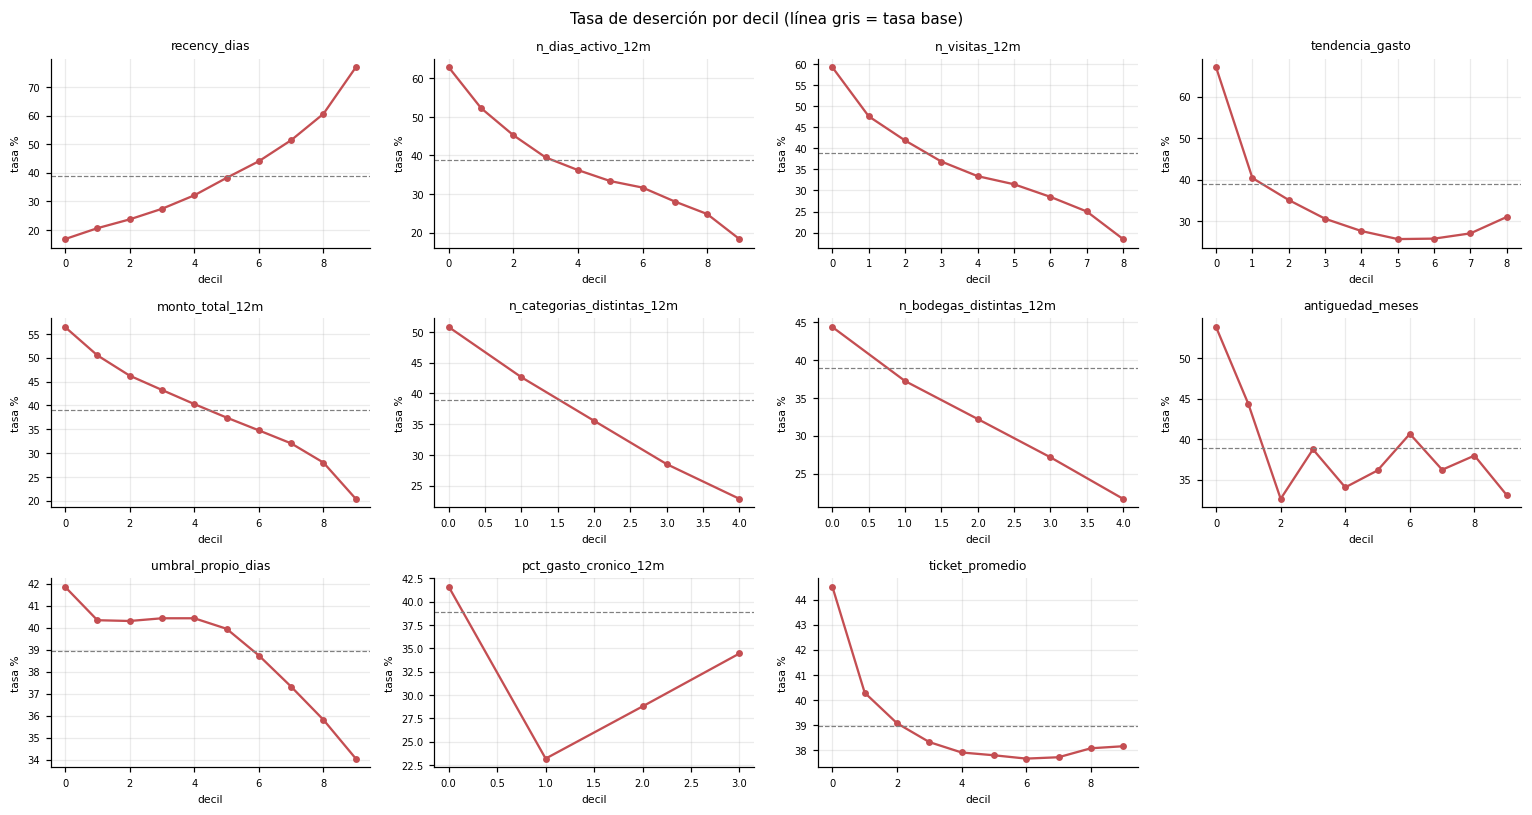

In [13]:
top = poder.head(12).index.tolist()
ncol = 4; nrow = int(np.ceil(len(top)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.5*ncol, 2.5*nrow))
base = df_e[TARGET].mean()
axes_flat = np.atleast_1d(axes).ravel()
for ax, col in zip(axes_flat, top):
    t = tasa_por_decil(col)
    ax.plot(range(len(t)), 100*t["mean"], "o-", color="#C44E52", ms=3.5)
    ax.axhline(100*base, ls="--", lw=.8, color="gray")
    ax.set_title(col, fontsize=8); ax.set_xlabel("decil", fontsize=7)
    ax.set_ylabel("tasa %", fontsize=7); ax.tick_params(labelsize=6.5)
for ax in axes_flat[len(top):]:
    ax.axis("off")
plt.suptitle("Tasa de deserción por decil (línea gris = tasa base)", fontsize=10)
plt.tight_layout(); plt.show()

## 4.9 Variables categóricas

El SQL simplificado dejó una sola variable categórica, `metodo_pago_principal_12m`
(las demás del diseño anterior — PDV, línea de producto, sexo — se retiraron al
simplificar la consulta, ver `CONTEXTO_PROYECTO.md` sección 6). Aun con una sola
columna interesa lo mismo que antes: cuántas categorías hay, cuántas cubren la
mayoría de los clientes, y si la tasa de churn varía de verdad entre ellas.

In [14]:
print("— cardinalidad y cobertura —")
filas = []
for c in FEAT_CAT:
    vc = df_e[c].value_counts(dropna=False)
    cum = vc.cumsum() / vc.sum()
    filas.append({
        "columna": c,
        "categorias": df_e[c].nunique(dropna=True),
        "nulos_%": round(100*df_e[c].isna().mean(), 2),
        "top1_%": round(100*vc.iloc[0]/vc.sum(), 1),
        "n_para_80%": int((cum < .80).sum() + 1),
        "n_para_95%": int((cum < .95).sum() + 1),
        "cats_con_<1%": int((vc/vc.sum() < .01).sum()),
    })
print(pd.DataFrame(filas).to_string(index=False))

— cardinalidad y cobertura —
                  columna  categorias  nulos_%  top1_%  n_para_80%  n_para_95%  cats_con_<1%
metodo_pago_principal_12m          14   0.0000 91.3000           1           3            10


In [15]:
# tasa de deserción por categoría (solo las que superan el 1 % de la base)
for c in FEAT_CAT:
    t = tasa_por(c).sort_values("n", ascending=False)
    t = t[t["pct_base"] >= 1.0].head(12)
    disp = t["tasa_%"].max() - t["tasa_%"].min() if len(t) > 1 else 0
    print(f"— {c} — (dispersión entre categorías: {disp:.1f} p.p.)")
    print(t.to_string(), "\n")

— metodo_pago_principal_12m — (dispersión entre categorías: 16.9 p.p.)
                                 n  desertores  tasa_%  pct_base
metodo_pago_principal_12m                                       
EFE                        1857861      721875 38.8600   91.2900
DEB                          64016       28345 44.2800    3.1500
CRP                          45217       12394 27.4100    2.2200
TAR                          45171       18397 40.7300    2.2200 



## 4.10 Umbral propio frente a una regla fija de 90 días — ya no reproducible tal cual

En el diseño anterior esta sección cruzaba `y_evento` (etiqueta con umbral
personalizado) contra `y_fijo90` (silencio > 90 días durante la ventana de
predicción), calculadas ambas en el SQL de 21 CTEs a partir del gap máximo
observado en el futuro (`max_gap_pred`).

**El SQL simplificado (19/09/2026) ya no calcula `max_gap_pred` ni un resultado
paralelo con la regla fija.** Solo guarda `churn`, la etiqueta con el umbral
personalizado. Reconstruir la comparación exigiría agregar de nuevo esa lógica
al SQL (una CTE que mire, para cada cliente, si su silencio máximo dentro de la
ventana de predicción superó los 90 días) — no se hizo aquí porque no era lo
que se pidió (dividir el notebook en dos, no reabrir el SQL).

Lo que sí se puede mostrar con las columnas actuales es una versión más
limitada: qué tan lejos está el umbral personalizado de cada cliente de un
valor fijo de 90 días. No es un cruce de resultados observados, es solo una
descripción de cuánto se aleja la personalización de una regla única.

— distribución de umbral_propio_dias frente a 90 días fijos —
clientes con umbral < 90 días (la regla fija los avisaría tarde): 1,655,867 (81.36 %)
clientes con umbral > 90 días (la regla fija los marcaría sin motivo): 364,007 (17.89 %)
clientes con umbral ≈ 90 días (±5 días): 168,801 (8.29 %)

— umbral medio por segmento —
                       mean  median  min  max
segmento_frecuencia                          
1. baja             71.7000 75.0000   14  120
2. media            69.7000 70.0000   14  120
3. alta             35.2000 33.0000   14  120


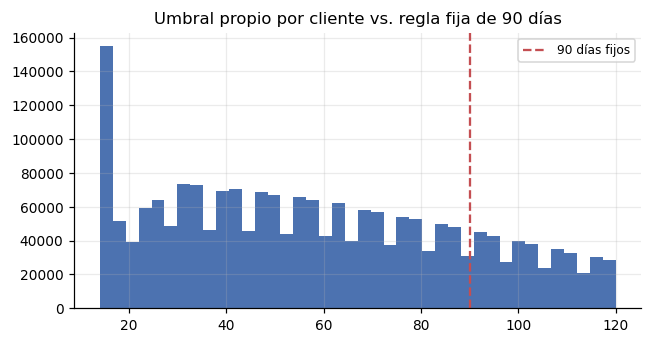

In [16]:
umbral = df_e["umbral_propio_dias"]
print("— distribución de umbral_propio_dias frente a 90 días fijos —")
print(f"clientes con umbral < 90 días (la regla fija los avisaría tarde): "
      f"{(umbral < 90).sum():,} ({100*(umbral < 90).mean():.2f} %)")
print(f"clientes con umbral > 90 días (la regla fija los marcaría sin motivo): "
      f"{(umbral > 90).sum():,} ({100*(umbral > 90).mean():.2f} %)")
print(f"clientes con umbral ≈ 90 días (±5 días): "
      f"{(umbral.between(85, 95)).sum():,} "
      f"({100*(umbral.between(85, 95)).mean():.2f} %)")

print("\n— umbral medio por segmento —")
print((df_e.groupby("segmento_frecuencia", observed=True)["umbral_propio_dias"]
       .agg(["mean", "median", "min", "max"]).round(1)).to_string())

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(umbral.clip(0, 200), bins=40, color="#4C72B0")
ax.axvline(90, color="#C44E52", ls="--", label="90 días fijos")
ax.set_title("Umbral propio por cliente vs. regla fija de 90 días")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.11 Búsqueda activa de fuga de información

Dos verificaciones, adaptadas al esquema simplificado (ya no hay `max_gap_pred`,
`y_estado` ni `y_fijo90` que comprobar: no existen en este diseño).

**Columnas de etiqueta fuera de las features.** `churn` (y `censurado`, que
define la población entrenable) no pueden entrar como features.

**`umbral_propio_dias` participa de la definición de la etiqueta.** No es fuga
en sentido estricto —se calcula solo con datos previos al corte—, pero crea una
relación mecánica: un cliente con umbral pequeño es más fácil de «disparar» que
uno con umbral grande, independientemente de su comportamiento futuro real. Por
eso el notebook de modelado debe entrenar **dos versiones, con y sin
`umbral_propio_dias`**, y comparar. Si el rendimiento se derrumba al quitarlo,
el modelo estaba aprendiendo la regla de etiquetado más que la señal de fuga.

In [17]:
print("— 1. columnas de etiqueta fuera de features —")
prohibidas = COLS_ETIQUETA + ["censurado"]
intrusas = [c for c in prohibidas if c in FEATURES]
print("OK: ninguna" if not intrusas else f"ERROR: {intrusas}")

print("\n— 2. bloque ligado a la definición de la etiqueta —")
BLOQUE_UMBRAL = ["umbral_propio_dias"]
print("a excluir en el análisis de sensibilidad del modelado:", BLOQUE_UMBRAL)
print("(en el diseño anterior este bloque tenía 3 columnas — gap_medio_dias,"
      " umbral_dias, ratio_recency_umbral —; el SQL simplificado solo"
      " conserva el equivalente de umbral_dias)")

— 1. columnas de etiqueta fuera de features —
OK: ninguna

— 2. bloque ligado a la definición de la etiqueta —
a excluir en el análisis de sensibilidad del modelado: ['umbral_propio_dias']
(en el diseño anterior este bloque tenía 3 columnas — gap_medio_dias, umbral_dias, ratio_recency_umbral —; el SQL simplificado solo conserva el equivalente de umbral_dias)


## 4.12 Resumen de hallazgos

Completar tras ejecutar sobre los datos reales. Las preguntas que esta sección
debe responder:

1. ¿La tasa base de `churn` es estable entre los cinco cortes? Si no, ¿qué
   corte se desvía y por qué?
2. ¿Cuál es la tasa base final y cuántos clientes entrenables quedan por corte?
3. ¿Qué features muestran mayor separación entre deciles extremos?
4. ¿Hay pares con correlación por encima de 0,75 que convenga eliminar?
5. ¿`pct_gasto_cronico_12m` está en cero para todos? Si sí, el valor de la
   bandera `producto_cronico` no era el asumido y hay que corregir `ESQUEMA`
   en `01_desercion_dataset.ipynb`.
6. ¿Qué tan lejos está el umbral propio de la regla fija de 90 días, y en qué
   segmento? (ver 4.10 — comparación parcial, no un cruce de resultados)
7. ¿`metodo_pago_principal_12m` concentra la mayoría de los clientes en pocas
   categorías, o está repartido?